# Seminar 6. Thermomechanical stress and deformation of a valve

**Axisymmetric linear elasticity · triangular finite elements · mechanical and thermal loading**

**Objective:** determine valve displacements and stresses from its meridional section using **the same mesh and temperature field** obtained in Seminar 4.

**Links to previous work:**

- **Seminar 3 (piston):** axisymmetric heat conduction, triangular shape functions, the factor $2\pi r$, and integration over a surface of revolution.
- **Seminar 4 (valve):** the existing `nodes.csv`, `elements.csv`, `boundary.json`, and `temp.csv` files.
- **Seminar 5 (Kirsch problem):** two degrees of freedom per node, the global stiffness matrix, and stress recovery; **its plane-stress matrices must not be transferred directly to the valve model**.

**Workflow:** data and geometry → physical model → matrices $\mathbf D$ and $\mathbf B$ → stiffness assembly → axisymmetric loads → displacement constraints → solution → displacements and stresses → thermoelastic analysis and comparison of results.

All calculations use **SI units**: $r,z,u_r,u_z$ in m, $E,\sigma,p$ in Pa, forces in N, and temperatures in °C (temperature differences in °C and K are equivalent).

## 1. Importing analysis data

The model is a meridional section of the valve in coordinates $(r,z)$, revolved about the axis $r=0$. We use data from the previous thermal analysis: the mesh must not be regenerated or renumbered, otherwise the temperatures will no longer correspond to the nodes of the structural model. **This is essential; otherwise the temperature field would have to be recalculated separately.**

The `_import` directory contains four files:

| File | Purpose | Shape |
|:--|:--|:--|
| `nodes.csv` | Nodal coordinates $(r,z)$, m | `(nn, 2)` |
| `elements.csv` | Indices of the three vertices, using zero-based numbering | `(ne, 3)` |
| `temp.csv` | Temperatures at the same nodes, °C | `(nn,)` |
| `boundary.json` | Dictionary of physical groups, boundary edges, and edge lengths | — |

**Gmsh is not required** to work with the exported mesh: NumPy, Matplotlib, and the Python standard library are sufficient.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

mesh_dir = Path("_import")

In [2]:
pnts = np.loadtxt(mesh_dir / "nodes.csv", delimiter=",", skiprows=1, ndmin=2)
elms = np.loadtxt(mesh_dir / "elements.csv", delimiter=",", skiprows=1, dtype=int, ndmin=2)
T_sol = np.loadtxt(mesh_dir / "temp.csv", delimiter=",", skiprows=1, dtype=float, ndmin=2).ravel()       # Flatten the temperature array from (742, 1) to (742,).
with open(mesh_dir / "boundary.json", encoding="utf-8") as f:
    boundary = json.load(f)

In [3]:
# Store the node and element counts for the assembly loops.
nn = len(pnts)
ne = len(elms) 

### 1.1. Geometry and physical groups

Four groups are relevant to the structural problem: `axis` is the axis of revolution; `seat_face` is the seating face; `cc_face` is the combustion-chamber side of the valve head; and `top_face` is the region where the valve-train load is applied. The remaining groups (`channel_face`, `contact_face`) are retained as boundary regions because the same model was used in the thermal analysis, where these groups defined boundary conditions. However, no external tractions are prescribed on them in the **current structural formulation**.

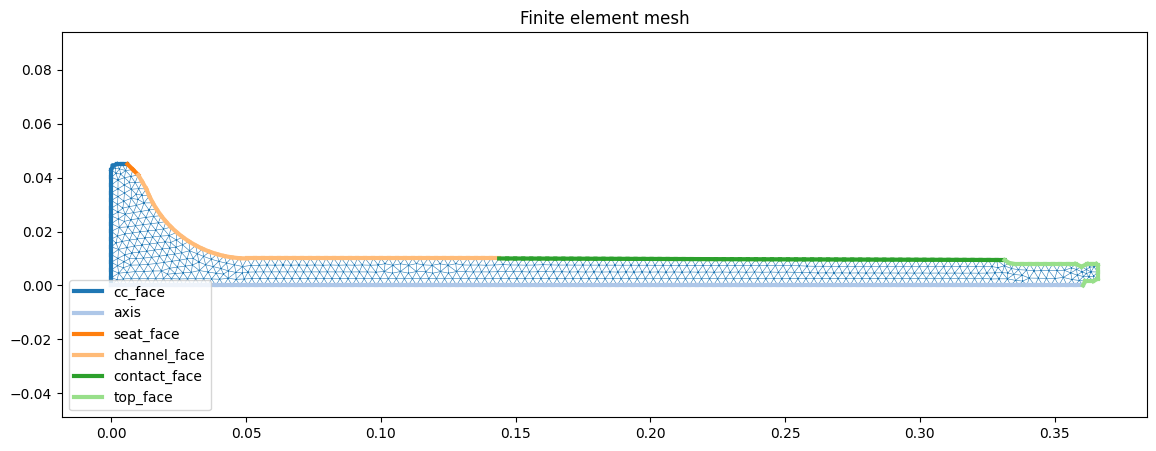

In [4]:
# Display all physical groups.
colors = plt.get_cmap("tab20").colors
# Create the figure.
fig, ax = plt.subplots(figsize=(14,5))
plt.title('Finite element mesh')
ax.triplot(pnts[:,1]  , pnts[:,0]  , elms, linewidth=0.4)
for i, bc in enumerate(boundary):
    edges = boundary[bc]['edges']
    plt.plot(pnts[edges, 1].T, pnts[edges, 0].T, color=colors[i], lw=3)
    plt.plot([], [], color=colors[i], lw=3, label=bc)
plt.axis('equal')
plt.legend(loc='lower left')
plt.show()

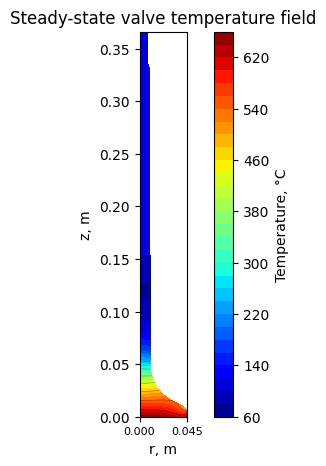

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
field = ax.tricontourf(pnts[:, 0] , pnts[:, 1] ,
                       elms, T_sol, levels=30, cmap="jet")
ax.tricontour(pnts[:, 0] , pnts[:, 1],
              elms, T_sol, levels=10, colors="black", linewidths=0.3, alpha=0.5)
fig.colorbar(field, ax=ax, label="Temperature, °C")
ax.set(xlabel="r, m", ylabel="z, m", title="Steady-state valve temperature field")
ax.set_aspect("equal")
ax.set_xticks(np.linspace(*ax.get_xlim(), 2))
ax.tick_params(axis="x", labelsize=8)
plt.show()

## 2. Physical formulation of the axisymmetric elasticity problem

We assume small strains, a homogeneous isotropic linear-elastic material, and fields independent of the angle $\varphi$. Unlike the **plane-stress formulation** used in the Kirsch problem, this model is expressed in cylindrical coordinates. The circumferential strain $\varepsilon_{\varphi\varphi}$ and stress $\sigma_{\varphi\varphi}$ are therefore generally **nonzero**.

The unknowns at each node are:

$$\mathbf u_i=\begin{pmatrix}u_{r,i}\\u_{z,i}\end{pmatrix},\qquad
\mathbf U_e=\begin{pmatrix}u_{r,i}&u_{z,i}&u_{r,j}&u_{z,j}&u_{r,m}&u_{z,m}\end{pmatrix}^{\mathsf T}.$$

The four independent strain components are:

$$
\boldsymbol\varepsilon=\begin{pmatrix}
\varepsilon_{rr}\\\varepsilon_{zz}\\\varepsilon_{\varphi\varphi}\\\gamma_{rz}
\end{pmatrix}
=\begin{pmatrix}
\partial u_r/\partial r\\
\partial u_z/\partial z\\
u_r/r\\
\partial u_r/\partial z+\partial u_z/\partial r
\end{pmatrix}.
$$

Here, $\gamma_{rz}$ is the **engineering shear strain**, not the tensorial shear strain. On the axis $r=0$, we impose $u_r=0$ as a regularity condition. Within an element, $\varepsilon_{\varphi\varphi}$ is evaluated at its centroid, where $\bar r_e>0$, to avoid division by zero at an axis node.

### 2.1. Material and loads

For this instructional analysis, we use:

- $E$: Young's modulus; $\nu$: Poisson's ratio;
- `Pz`: the **axial component of surface traction** on `cc_face`, positive in the $+z$ direction;
- `Pax`: the axial component of surface traction on `top_face`, acting in the $-z$ direction;
- `alph_t`: the coefficient of thermal expansion.

In [6]:
# Input parameters (SI units)
Pax = -4e6            # Pa: axial surface traction in the z direction
Pz  = 19E6            # Pa: axial surface traction in the z direction
E = 210e9             # Pa: Young's modulus
nu = 0.30             # Poisson's ratio
alph_t = 1.23e-5      # 1/K: coefficient of linear thermal expansion

## 3. Elastic constitutive matrix $\mathbf D$

Axisymmetric **three-dimensional** isotropic elasticity uses the Lamé parameters

$$\lambda_L=\frac{E\nu}{(1+\nu)(1-2\nu)},\qquad G=\frac{E}{2(1+\nu)}.$$

For the chosen component order $(rr,zz,\varphi\varphi,rz)$:

$$
\boxed{\mathbf D=\begin{pmatrix}
\lambda_L+2G&\lambda_L&\lambda_L&0\\
\lambda_L&\lambda_L+2G&\lambda_L&0\\
\lambda_L&\lambda_L&\lambda_L+2G&0\\
0&0&0&G
\end{pmatrix}}.
$$

Hooke's law for the **mechanical-only stage** is $\boldsymbol\sigma=\mathbf D\boldsymbol\varepsilon$, where $\boldsymbol\sigma=(\sigma_{rr},\sigma_{zz},\sigma_{\varphi\varphi},\tau_{rz})^{\mathsf T}$. This expression differs from the $3\times3$ plane-stress matrix used in the Kirsch problem.

In [7]:
# Axisymmetric constitutive matrix; component order: (rr, zz, hoop, rz).
lmbda = E * nu / ((1 + nu) * (1 - 2 * nu))
G = E / (2 * (1 + nu))
D = np.array([
    [lmbda + 2*G, lmbda,       lmbda,       0],
    [lmbda,       lmbda + 2*G, lmbda,       0],
    [lmbda,       lmbda,       lmbda + 2*G, 0],
    [0,           0,           0,           G]
])

## 4. Axisymmetric triangular finite element

### 4.1. Displacement approximation within an element

Consider a linear triangular finite element with nodes $i$, $j$, and $m$ in the meridional plane $(r,z)$, as in the previous problems.

Two displacement components are determined at each node: the radial component $u_r$ and the axial component $u_z$. The element nodal displacement vector is:

$$
\mathbf U_e=
\begin{bmatrix}
u_{r,i}&u_{z,i}&u_{r,j}&u_{z,j}&u_{r,m}&u_{z,m}
\end{bmatrix}^{\mathsf T}.
$$

As in the piston heat-conduction problem, the unknown fields within the element are approximated using the linear shape functions $N_i(r,z)$, $N_j(r,z)$, and $N_m(r,z)$:

$$
\boxed{
\begin{aligned}
u_r(r,z)&=N_i u_{r,i}+N_j u_{r,j}+N_m u_{r,m},\\
u_z(r,z)&=N_i u_{z,i}+N_j u_{z,j}+N_m u_{z,m}.
\end{aligned}
}
$$

The shape functions define how nodal displacements are interpolated at an arbitrary point within the element.

### 4.2. Deriving the shape functions and their derivatives

For a linear triangle, each shape function is linear in the coordinates:

$$
N_a(r,z)=\alpha_a+\beta_a r+\gamma_a z.
$$

Its coefficients are determined by requiring the shape function to equal one at its own node and zero at the other nodes.

For example, for node $i$:

$$
N_i(r_i,z_i)=1,\qquad
N_i(r_j,z_j)=N_i(r_m,z_m)=0.
$$

The coefficients of $N_i$ are therefore obtained by solving:

$$
\begin{bmatrix}
1&r_i&z_i\\
1&r_j&z_j\\
1&r_m&z_m
\end{bmatrix}
\begin{bmatrix}
\alpha_i\\
\beta_i\\
\gamma_i
\end{bmatrix}
=
\begin{bmatrix}
1\\0\\0
\end{bmatrix}.
$$

The determinant of the geometric matrix equals twice the signed area of the triangle:

$$
2A_{or}=
\begin{vmatrix}
1&r_i&z_i\\
1&r_j&z_j\\
1&r_m&z_m
\end{vmatrix}.
$$

After solving the system, the shape functions can be written as:

$$
\boxed{
N_a(r,z)=\frac{a_a+b_a r+c_a z}{2A_{or}}
}
$$

where the coefficients for the three nodes are determined by the element geometry:

$$
\begin{aligned}
\mathbf a&=
\begin{pmatrix}
r_jz_m-r_mz_j\\
r_mz_i-r_iz_m\\
r_iz_j-r_jz_i
\end{pmatrix},\\[6pt]
\mathbf b&=
\begin{pmatrix}
z_j-z_m\\
z_m-z_i\\
z_i-z_j
\end{pmatrix},\\[6pt]
\mathbf c&=
\begin{pmatrix}
r_m-r_j\\
r_i-r_m\\
r_j-r_i
\end{pmatrix}.
\end{aligned}
$$

Since the coefficients $a_a$, $b_a$, and $c_a$ and the area $A_{or}$ are constant for a given element, the shape-function derivatives follow directly by differentiation:

$$
\frac{\partial N_a}{\partial r}
=
\frac{\partial}{\partial r}
\left(
\frac{a_a+b_a r+c_a z}{2A_{or}}
\right)
=
\boxed{\frac{b_a}{2A_{or}}},
$$

$$
\frac{\partial N_a}{\partial z}
=
\frac{\partial}{\partial z}
\left(
\frac{a_a+b_a r+c_a z}{2A_{or}}
\right)
=
\boxed{\frac{c_a}{2A_{or}}}.
$$

Thus, the shape-function derivatives are constant within a linear triangular element.

### 4.3. From displacements to strains

For the axisymmetric problem, we assume:

$$
\frac{\partial}{\partial\varphi}=0,\qquad
u_\varphi=0.
$$

The strain vector has four components:

$$
\boldsymbol{\varepsilon}=
\begin{bmatrix}
\varepsilon_{rr}\\
\varepsilon_{zz}\\
\varepsilon_{\varphi\varphi}\\
\gamma_{rz}
\end{bmatrix}
=
\begin{bmatrix}
\dfrac{\partial u_r}{\partial r}\\[4pt]
\dfrac{\partial u_z}{\partial z}\\[4pt]
\dfrac{u_r}{r}\\[4pt]
\dfrac{\partial u_r}{\partial z}+
\dfrac{\partial u_z}{\partial r}
\end{bmatrix}.
$$

Substitute the displacement approximation into the strain expressions.

For example, the radial strain is:

$$
\begin{aligned}
\varepsilon_{rr}
&=\frac{\partial u_r}{\partial r}\\
&=\frac{\partial N_i}{\partial r}u_{r,i}
+\frac{\partial N_j}{\partial r}u_{r,j}
+\frac{\partial N_m}{\partial r}u_{r,m}.
\end{aligned}
$$

The axial strain is:

$$
\varepsilon_{zz}
=
\frac{\partial N_i}{\partial z}u_{z,i}
+\frac{\partial N_j}{\partial z}u_{z,j}
+\frac{\partial N_m}{\partial z}u_{z,m}.
$$

The circumferential strain is:

$$
\varepsilon_{\varphi\varphi}
=
\frac{N_i}{r}u_{r,i}
+\frac{N_j}{r}u_{r,j}
+\frac{N_m}{r}u_{r,m}.
$$

The shear strain is:

$$
\gamma_{rz}
=
\sum_{a=i,j,m}
\left(
\frac{\partial N_a}{\partial z}u_{r,a}
+
\frac{\partial N_a}{\partial r}u_{z,a}
\right).
$$

These relations can be combined in matrix form:

$$
\boxed{
\boldsymbol{\varepsilon}=\mathbf B_e\mathbf U_e.
}
$$

For a single node $a$, the strain-displacement matrix is:

$$
\mathbf B_a(r,z)=
\begin{bmatrix}
N_{a,r}&0\\
0&N_{a,z}\\
N_a/r&0\\
N_{a,z}&N_{a,r}
\end{bmatrix}.
$$

Combining the contributions from the three nodes gives a $4\times6$ matrix:

$$
\boxed{
\mathbf B_e=
\begin{bmatrix}
N_{i,r}&0&N_{j,r}&0&N_{m,r}&0\\
0&N_{i,z}&0&N_{j,z}&0&N_{m,z}\\
N_i/r&0&N_j/r&0&N_m/r&0\\
N_{i,z}&N_{i,r}&N_{j,z}&N_{j,r}&N_{m,z}&N_{m,r}
\end{bmatrix}.
}
$$

**The main difference from a planar formulation is the third row of $\mathbf B_e$.** It accounts for the circumferential strain $\varepsilon_{\varphi\varphi}=u_r/r$ caused by the change in radius and, consequently, in circumference as the body of revolution deforms.

### 4.4. Evaluating the strain-displacement matrix at the element centroid

In this implementation, $\mathbf B_e$ is evaluated at the centroid of the triangular element.

At the centroid of a linear triangle:

$$
N_i=N_j=N_m=\frac13,
\qquad
\bar r=\frac{r_i+r_j+r_m}{3}.
$$

The contribution of each node to the strain-displacement matrix can therefore be written as:

$$
\boxed{
\mathbf B_a(\bar r)=
\begin{bmatrix}
\dfrac{b_a}{2A_{or}}&0\\[6pt]
0&\dfrac{c_a}{2A_{or}}\\[6pt]
\dfrac{1}{3\bar r}&0\\[6pt]
\dfrac{c_a}{2A_{or}}&\dfrac{b_a}{2A_{or}}
\end{bmatrix}.
}
$$

The full matrix is formed by combining the three blocks:

$$
\mathbf B_e=
\begin{bmatrix}
\mathbf B_i&\mathbf B_j&\mathbf B_m
\end{bmatrix}.
$$

Note that the derivatives $N_{a,r}$ and $N_{a,z}$ are constant within a linear element, whereas the ratio $N_a/r$ depends on position.

Evaluating $\mathbf B_e$ at the element centroid is therefore an approximation.

### 4.5. Forming the element stiffness matrix

For axisymmetric elasticity, the element stiffness matrix is defined by:

$$
\mathbf K_e=
\int_{V_e}
\mathbf B_e^{\mathsf T}\mathbf D\mathbf B_e\,dV,
$$

where $\mathbf D$ is the $4\times4$ elastic constitutive matrix.

As in the axisymmetric piston heat-conduction problem, the meridional section is related to the volume of the body of revolution through:

$$
dV=2\pi r\,dA.
$$

Hence:

$$
\boxed{
\mathbf K_e=
\int_{A_e}
2\pi r\,
\mathbf B_e^{\mathsf T}\mathbf D\mathbf B_e\,dA.
}
$$

Using quadrature at the triangle centroid gives:

$$
\boxed{
\mathbf K_e\approx
2\pi\bar r A_e\,
\mathbf B_e^{\mathsf T}(\bar r)
\mathbf D
\mathbf B_e(\bar r),
}
$$

where:

- $A_e=|A_{or}|$ is the positive area of the triangle;
- $\bar r$ is the radial coordinate of the element centroid;
- $\mathbf B_e(\bar r)$ is the strain-displacement matrix evaluated at the element centroid;
- $\mathbf D$ is the material elastic constitutive matrix.

**Analogy with the piston analysis.**

In heat conduction with linear triangular elements, the temperature gradient is constant. The radial factor $r$ can therefore be integrated exactly using the centroid coordinate.

In axisymmetric elasticity, $\mathbf B_e$ contains the ratio $N_a/r$, which varies within the element. Consequently, centroid quadrature gives an approximate element stiffness matrix.

Higher-order numerical integration may be needed to improve accuracy, particularly near the axis of revolution. Quadratic elements are often used in structural analysis, where the choice of integration rule must also be considered.

In [8]:
def get_kel(element):
    i , j , m = element
    ri, zi = pnts[i]
    rj, zj = pnts[j]
    rm, zm = pnts[m]
    r_avg = (ri + rj + rm) / 3.0                       # Element centroid radius, m  
    area = 0.5 * abs((rj-ri)*(zm-zi) - (zj-zi)*(rm-ri))
    bi, bj, bm =  zj-zm, zm-zi, zi-zj
    ci, cj, cm =  rm-rj, ri-rm, rj-ri
    B = 1 / (2 *area) * np.array([
            [bi,                 0,         bj,                 0,     bm,                 0 ],
            [0,                  ci,        0,                  cj,    0,                  cm],
            [2*area/(3*r_avg),   0,         2*area/(3*r_avg),   0,     2*area/(3*r_avg),   0],                       # Evaluate the circumferential strain terms at the element centroid.
            [ci,                 bi,        cj,                 bj,    cm,                 bm]])
    Kel = 2*np.pi*r_avg*area*(B.T @ D @ B)                                  # Use matrix multiplication, not elementwise multiplication.
    return Kel, B

## 5. Assembly of the global stiffness matrix

Each node has **two** degrees of freedom, $u_r,u_z$. The global matrix therefore has dimensions $(2nn)\times(2nn)$. For an element with vertices $(i,j,m)$, the corresponding indices are $(2i,2i+1,2j,2j+1,2m,2m+1)$.

The assembly $\mathbf K=\sum_e\mathbf A_e^{\mathsf T}\mathbf K_e\mathbf A_e$ follows the same principle as the global heat-conduction matrix in the piston problem, except that the thermal problem had only one unknown, $T_i$, per node.

In [9]:
Kglob = np.zeros((2*nn, 2*nn))
Fglob = np.zeros(2*nn)

In [10]:
# Use np.ix_ to select the submatrix for the element DOFs.
for el in range(ne):
    # Each node now has two consecutive displacement DOFs.
    i, j, m =elms[el]
    Kel, _ = get_kel(elms[el])
    # Indices of the six element degrees of freedom
    IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1], dtype=int)             # Indices must be integers.
    IndXArr = np.ix_(IndX, IndX)
    # Assemble the element stiffness into the global matrix.
    Kglob[IndXArr] += Kel 

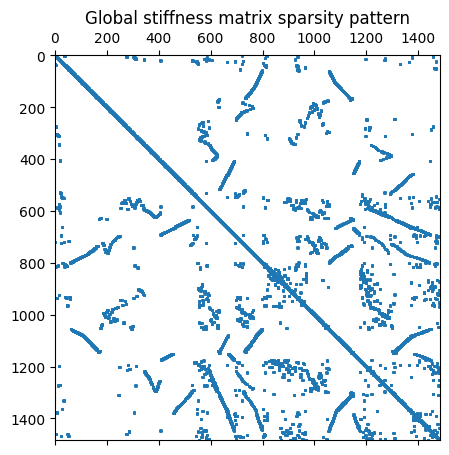

In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.spy(Kglob, markersize=1)
ax.set_title("Global stiffness matrix sparsity pattern")
plt.show()

## 6. Boundary conditions and loads

On the axis of symmetry, $u_r=0$, while axial displacement is unconstrained. On the seating face, this **simplified** model uses a bilateral sliding support: $u_r+u_z=0$, with tangential displacement left free, as described in Section 6.2. In a real valve-seat interface, contact may be unilateral and may involve friction or sliding. Complete restraint is therefore **not a universal contact condition** and may overestimate local stresses.

The external surface traction $\mathbf t=(p_r,p_z)$ is applied to the specified physical groups. Revolving a line segment of length $L$ generates a surface with $dS=2\pi r\,dL$, as in the convective (Robin) thermal boundary condition for the piston.

For a linear edge whose endpoint radii are $r_i,r_j$, the **consistent nodal load vector** is

$$
\boxed{
\mathbf F_{\Gamma,e}=\frac{\pi L}{3}
\begin{pmatrix}
(2r_i+r_j)p_r\\(2r_i+r_j)p_z\\
(r_i+2r_j)p_r\\(r_i+2r_j)p_z
\end{pmatrix}.}
$$

**Order of application:** first assemble the external force vector, **then** impose the displacement boundary conditions. Otherwise, a load added after zeroing the rows of constrained nodes may violate the prescribed displacements.

### 6.1. Displacement constraints and mechanical loading

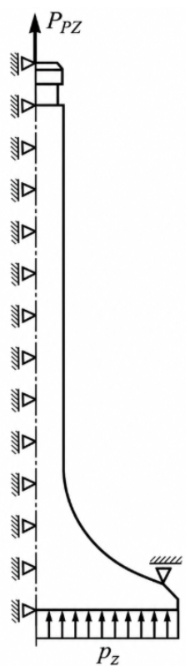

### 6.2. Normal restraint of the seating face with tangential sliding

In the Kirsch problem, we considered complete restraint:

$$
u_r=0,\qquad u_z=0.
$$

These conditions prevent all displacements of the seating-face nodes, including those caused by thermal expansion of the valve. This can lead to overestimation of local stresses.

In the refined formulation, we consider **smooth, frictionless contact between the valve and a stationary seat**. Displacement normal to the surface is constrained, while displacement along the surface is permitted.

For the convenient seating-face inclination of $45^\circ$, introduce the unit normal and tangent vectors:

$$
\mathbf n=\frac{1}{\sqrt{2}}
\begin{bmatrix}1\\1\end{bmatrix},
\qquad
\mathbf t=\frac{1}{\sqrt{2}}
\begin{bmatrix}1\\-1\end{bmatrix}.
$$

The normal and tangential displacement components are then:

$$
u_n=\mathbf u\cdot\mathbf n
=\frac{u_r+u_z}{\sqrt{2}},
$$

$$
u_t=\mathbf u\cdot\mathbf t
=\frac{u_r-u_z}{\sqrt{2}}.
$$

The condition of zero normal displacement is:

$$
\boxed{u_n=0\quad\Rightarrow\quad u_r+u_z=0.}
$$

The tangential displacement $u_t$ remains unconstrained.

Smooth contact also implies zero tangential contact reaction:

$$
\boxed{R_t=0\quad\Rightarrow\quad R_r-R_z=0,}
$$

where $R_r$ and $R_z$ are components of the nodal equilibrium residual vector before the contact constraint is imposed:

$$
\mathbf R=\mathbf K\mathbf U-\mathbf F.
$$

For each seating-face node, the two original equilibrium equations are therefore replaced by:

$$
\boxed{
\begin{cases}
u_r+u_z=0,\\
(\mathbf K_r-\mathbf K_z)\mathbf U=F_r-F_z.
\end{cases}
}
$$

The first equation prevents displacement normal to the seating face; the second enforces equilibrium in the tangential direction.

**Python implementation.**

In `bc_seat()`, the line

`K[ir, ir] = K[ir, iz] = 1.0`

imposes $u_r+u_z=0$, while the expression

`row_t = K[ir, :] - K[iz, :]`

forms the equilibrium equation along the seating face.

Unlike complete restraint, this formulation allows the valve to slide relative to the seat under mechanical loading and thermal expansion.

**Model limitations.** This formulation assumes continuous contact with a stationary seat, no friction, and a seating-face inclination of $45^\circ$ with the chosen normal direction. It does not account for possible separation of the valve from the seat or changes in the contact region. For an arbitrary seating-face inclination, the actual components of the normal and tangent vectors must be used.

In [12]:
def bc_disp(K, F, boundary, ur=np.nan, uz=np.nan):
    for nd in boundary['nodes']:
        # Prescribe the radial displacement.
        if not np.isnan(ur):
            idx = 2*nd
            K[idx, :] = 0
            K[idx, idx] = 1
            F[idx] = ur
        # Prescribe the axial displacement.
        if not np.isnan(uz):
            idx = 2 * nd + 1
            K[idx, :] = 0
            K[idx, idx] = 1
            F[idx] = uz
    return K, F

In [13]:
def bc_seat(K, F, boundary):
    for nd in boundary["nodes"]:
        ir, iz = 2*nd, 2*nd + 1   # Rows of the radial and axial equilibrium equations
        # Replace row 2*nd + 1 with tangential equilibrium along the seat face. 
        K[iz, :] = K[ir, :] - K[iz, :]
        F[iz] = F[ir] - F[iz]
        # Replace row 2*nd with the normal constraint: ur + uz = 0.
        K[ir, :] = 0.0
        F[ir] = 0.0
        K[ir, ir] = 1.0
        K[ir, iz] = 1.0
    return K, F

### 6.3. Axisymmetric surface traction

The `bc_pressure()` function is adapted from the Kirsch problem to axisymmetric surface loading. Each edge contribution is integrated over the corresponding surface of revolution, with consistent weighting of its endpoint radii. The prescribed `pr` and `pz` values are components of surface traction. Boundary edges and their lengths are read from `boundary.json`.

In [14]:
def bc_pressure(F, boundary,  pr=0.0, pz=0.0):
    edges = boundary['edges']
    L = boundary['length']
    for (i, j), length in zip(edges, L):
        ri, rj = pnts[i, 0], pnts[j, 0]
        IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1], dtype=int)
        F[IndX] += np.pi * length / 3 * np.array([pr, pz, pr, pz])*np.array([2*ri + rj, 2*ri + rj, ri + 2*rj, ri + 2*rj])       # The * operator performs elementwise multiplication of NumPy arrays.
    return F 

### 6.4. Applying loads before displacement constraints

First apply `Pax` to `top_face` and `Pz` to `cc_face`. Then constrain radial displacement on the axis and normal displacement on the seating face, while allowing tangential sliding.

In [15]:
K1 = Kglob.copy()
F1 = Fglob.copy()

In [16]:
# Apply the surface tractions FIRST.
F1 = bc_pressure(F1, boundary["top_face"], pr=0, pz=Pax)
F1 = bc_pressure(F1, boundary["cc_face"],  pr=0, pz=Pz)
# THEN impose the displacement boundary conditions.
K1, F1 = bc_disp(K1, F1, boundary["axis"], ur=0.0)
K1, F1 = bc_seat(K1, F1, boundary["seat_face"])

## 7. Solving the system and checking boundary conditions

We solve $\mathbf K\mathbf U=\mathbf F$, where

$$\mathbf U=(u_{r,0},u_{z,0},u_{r,1},u_{z,1},\ldots)^{\mathsf T}.$$

For plotting, the solution is arranged as a matrix of shape `(2, nn)`: the first row contains $u_r$ and the second contains $u_z$.

In [17]:
Disp = np.linalg.solve(K1, F1)
Disp2plot = Disp.reshape(-1, 2).T
Ur, Uz = Disp2plot
Usum = np.sqrt(Ur**2 + Uz**2)

### 7.1. Valve displacements

Plot $u_r$, $u_z$, and the magnitude $|\mathbf u|$. The nodal displacement fields are interpolated over the triangles for visualization. The color scales are displayed in micrometres (μm); the displacement arrays remain in metres.

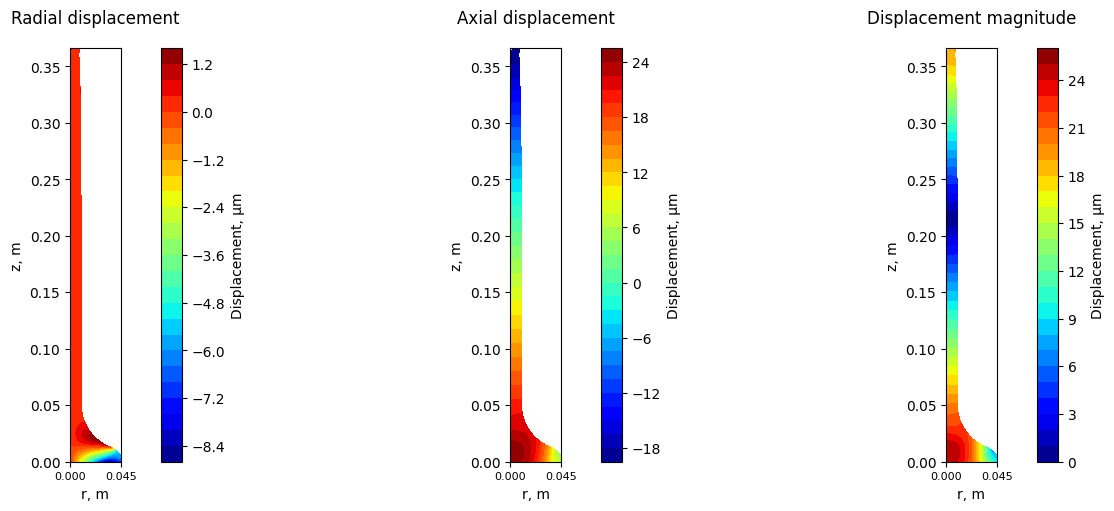

In [18]:
fields_u = [
    (Ur, "Radial displacement"),
    (Uz, "Axial displacement"),
    (Usum,  "Displacement magnitude")
]
fig, axs = plt.subplots(1, 3, figsize=(13, 5), constrained_layout=True)
for ax, (values, title) in zip(axs, fields_u):
    im = ax.tricontourf(pnts[:, 0], pnts[:, 1],
                        elms, values * 1e6, levels=30, cmap="jet")
    fig.colorbar(im, ax=ax, label="Displacement, μm", pad=0.08)
    ax.set(xlabel="r, m", ylabel="z, m")
    ax.set_title(title, pad=18)
    ax.set_xticks([pnts[:, 0].min(), pnts[:, 0].max()])
    ax.tick_params(axis="x", labelsize=8)
    ax.set_aspect("equal")
plt.show()

## 8. Strain and stress recovery

After solving the global system, a six-component vector $\mathbf U_e$ is formed for each triangle. The strains and stresses **at the element centroid** are

$$\boldsymbol\varepsilon_e=\mathbf B_e\mathbf U_e,\qquad
\boldsymbol\sigma_e=\mathbf D\boldsymbol\varepsilon_e.$$

Each field now has **four** components:

$$\boldsymbol\sigma_e=(\sigma_{rr},\sigma_{zz},\sigma_{\varphi\varphi},\tau_{rz})^{\mathsf T}.$$

In [19]:
# Stresses at the element centroids, Pa.
Sigma = np.zeros((ne, 4))
Eps   = np.zeros((ne, 4))
for el in range(ne):
    i, j, m = elms[el]
    _, B = get_kel(elms[el])
    # Indices of the six element degrees of freedom
    IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1], dtype=int)             # Indices must be integers.
    Uel = Disp[IndX]
    Eps[el] = B @ Uel
    Sigma[el] = D @ Eps[el]

### 8.1. Averaging element stresses at nodes

As discussed, stresses are constant within a linear element. To obtain a smooth visualization of the distribution, use the simple arithmetic mean over the triangles sharing a node:

$$\overline{\boldsymbol\sigma}_i=\frac{1}{n_i}\sum_{e\ni i}\boldsymbol\sigma_e.$$

Near a sharp boundary, the edge of a constrained region, or a stress concentrator, averaging smooths local peaks. **For engineering assessments, the unaveraged element values should be examined.**

In [20]:
Sigma_nodes = np.zeros((nn, 4))
count = np.zeros(nn, dtype=int)
for el in range(ne):
    nodes = elms[el]
    Sigma_nodes[nodes] += Sigma[el]
    count[nodes] += 1
Sigma_nodes /= count[:, None]
SR, SZ, STHETA, SRZ = Sigma_nodes.T

### 8.2. Stresses

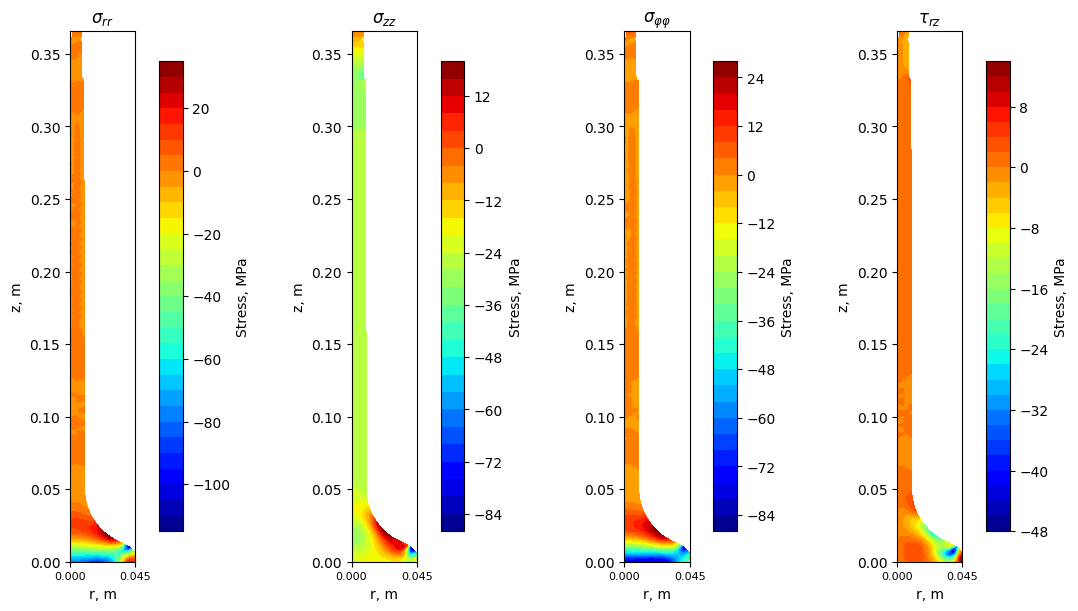

In [21]:
fields_sigma = [
    (SR,     r"$\sigma_{rr}$"),
    (SZ,     r"$\sigma_{zz}$"),
    (STHETA, r"$\sigma_{\varphi\varphi}$"),
    (SRZ,    r"$\tau_{rz}$")
]
fig, axs = plt.subplots(1, 4, figsize=(11, 6), constrained_layout=True)
for ax, (values, title) in zip(axs.flat, fields_sigma):
    im = ax.tricontourf(pnts[:, 0], pnts[:, 1],
                        elms, values/1e6, levels=30, cmap="jet")
    fig.colorbar(im, ax=ax, label="Stress, MPa")
    ax.set(xlabel="r, m", ylabel="z, m", title=title)
    ax.set_aspect("equal")
    ax.set_xticks(np.linspace(*ax.get_xlim(), 2))
    ax.tick_params(axis="x", labelsize=8)
plt.show()

### 8.3. Deformed mesh

Displacements can be magnified when plotting the mesh to make the deformation easier to see.

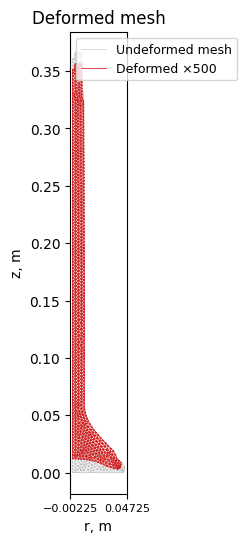

In [22]:
scale = 500.0                                                     # Displacement magnification factor for visualization
fig, ax = plt.subplots(figsize=(7, 6))
ax.triplot(pnts[:, 0], pnts[:, 1], elms,
           lw=0.4, color="0.75", label="Undeformed mesh")
ax.triplot((pnts[:, 0] + scale*Ur),
           (pnts[:, 1] + scale*Uz),
           elms, lw=0.6, color="tab:red", label=f"Deformed ×{scale:g}")
ax.set(xlabel="r, m", ylabel="z, m", title="Deformed mesh")
ax.set_aspect("equal")
ax.set_xticks(np.linspace(*ax.get_xlim(), 2))
ax.tick_params(axis="x", labelsize=8)
ax.legend(fontsize=9)
plt.show()

## 9. Incorporating thermal strains and stresses

So far, we have considered valve deformation caused only by mechanical loads, using Hooke's law:

$$
\boldsymbol{\sigma}=\mathbf D\boldsymbol{\varepsilon}
=\mathbf D\mathbf B_e\mathbf U_e.
$$

During operation, however, the valve heats nonuniformly. Temperature changes cause thermal expansion of the material, which must be included when determining displacements, strains, and stresses.

### 9.1. Decomposition of total strain into elastic and thermal parts

In linear thermoelasticity, total strain is the sum of two contributions:

$$
\boxed{
\boldsymbol{\varepsilon}
=
\boldsymbol{\varepsilon}_{el}
+
\boldsymbol{\varepsilon}_{T},
}
$$

where:

- $\boldsymbol{\varepsilon}_{el}$ is the elastic strain that produces mechanical stress;
- $\boldsymbol{\varepsilon}_{T}$ is the free thermal strain of the material.

For an isotropic material with equal thermal expansion in all directions:

$$
\boldsymbol{\varepsilon}_{T}
=
\alpha_T\Delta T
\begin{bmatrix}
1\\1\\1\\0
\end{bmatrix},
$$

where $\alpha_T$ is the coefficient of linear thermal expansion, in 1/K, and $\Delta T=T-T_{ref}$ is the temperature change relative to the initial state.

**Thermal strain does not generate stress by itself.** If the material can expand freely, no stresses develop. Stresses arise when thermal expansion is restricted by supports or by strain incompatibility between neighboring regions of the material.

Including thermal expansion, the elastic contribution is:

$$
\boldsymbol{\varepsilon}_{el}
=
\boldsymbol{\varepsilon}
-
\boldsymbol{\varepsilon}_{T}.
$$

Hooke's law must therefore be written as:

$$
\boxed{
\boldsymbol{\sigma}
=
\mathbf D
\left(
\boldsymbol{\varepsilon}
-
\boldsymbol{\varepsilon}_{T}
\right).
}
$$

Since the total strains are determined by the element nodal displacements:

$$
\boldsymbol{\varepsilon}=\mathbf B_e\mathbf U_e,
$$

we obtain:

$$
\boxed{
\boldsymbol{\sigma}_e
=
\mathbf D
\left(
\mathbf B_e\mathbf U_e
-
\boldsymbol{\varepsilon}_{T,e}
\right).
}
$$

This is the fundamental linear thermoelastic relation used in the valve analysis.

### 9.2. Incorporating thermal strains into the finite element equations

The element stiffness matrix was previously derived from the principle of virtual work:

$$
\int_{V_e}
\delta\boldsymbol{\varepsilon}^{\mathsf T}
\boldsymbol{\sigma}\,dV
=
\delta\mathbf U_e^{\mathsf T}\mathbf F_{mech,e},
$$

where $\mathbf F_{mech,e}$ is the equivalent nodal mechanical load vector.

For a finite element:

$$
\delta\boldsymbol{\varepsilon}
=
\mathbf B_e\delta\mathbf U_e.
$$

Substitute Hooke's law including thermal strain:

$$
\int_{V_e}
\delta\mathbf U_e^{\mathsf T}
\mathbf B_e^{\mathsf T}
\mathbf D
\left(
\mathbf B_e\mathbf U_e
-
\boldsymbol{\varepsilon}_{T,e}
\right)dV
=
\delta\mathbf U_e^{\mathsf T}\mathbf F_{mech,e}.
$$

Since the virtual nodal displacements are arbitrary, this gives:

$$
\int_{V_e}
\mathbf B_e^{\mathsf T}\mathbf D\mathbf B_e\,dV
\;\mathbf U_e
-
\int_{V_e}
\mathbf B_e^{\mathsf T}\mathbf D
\boldsymbol{\varepsilon}_{T,e}\,dV
=
\mathbf F_{mech,e}.
$$

The first integral is the familiar element stiffness matrix:

$$
\mathbf K_e
=
\int_{V_e}
\mathbf B_e^{\mathsf T}\mathbf D\mathbf B_e\,dV.
$$

The second integral defines the **equivalent nodal thermal force vector**:

$$
\boxed{
\mathbf F_{T,e}
=
\int_{V_e}
\mathbf B_e^{\mathsf T}\mathbf D
\boldsymbol{\varepsilon}_{T,e}\,dV.
}
$$

The element equilibrium equation therefore becomes:

$$
\boxed{
\mathbf K_e\mathbf U_e
=
\mathbf F_{mech,e}
+
\mathbf F_{T,e}.
}
$$

**Thermal strains are thus included through an additional equivalent nodal force vector on the right-hand side of the finite element equations.**

For constant elastic material properties, the stiffness matrix $\mathbf K_e$ remains unchanged.

After assembly over all finite elements, the global system is:

$$
\boxed{
\mathbf K_{glob}\mathbf U
=
\mathbf F_{mech}
+
\mathbf F_T.
}
$$

Here, $\mathbf F_T$ is not an external mechanical load. It is a mathematically equivalent representation of the effect of thermal strain on structural equilibrium.

### 9.3. Thermal loading of an axisymmetric element

As when forming the element stiffness matrix, the axisymmetric formulation uses:

$$
dV=2\pi r\,dA.
$$

The thermal force vector is therefore:

$$
\mathbf F_{T,e}
=
\int_{A_e}
2\pi r\,
\mathbf B_e^{\mathsf T}
\mathbf D
\boldsymbol{\varepsilon}_{T,e}\,dA.
$$

The nodal temperatures $T_i,T_j,T_m$ are obtained from the previous thermal analysis of the valve.

Within the element, temperature is interpolated using the same linear shape functions:

$$
T(r,z)=N_iT_i+N_jT_j+N_mT_m.
$$

At the triangle centroid, $N_i=N_j=N_m=1/3$, so:

$$
\boxed{
\Delta T_e=
\frac{T_i+T_j+T_m}{3}-T_{ref}.
}
$$

Accordingly:

$$
\boldsymbol{\varepsilon}_{T,e}
=
\alpha_T\Delta T_e
\begin{bmatrix}
1\\1\\1\\0
\end{bmatrix}.
$$

Using centroid quadrature, consistently with the adopted evaluation of $\mathbf B_e$, gives:

$$
\boxed{
\mathbf F_{T,e}
\approx
2\pi\bar r_e A_e
\mathbf B_e^{\mathsf T}
\mathbf D
\boldsymbol{\varepsilon}_{T,e}.
}
$$

For an isotropic material with constant $E$, $\nu$, and $\alpha_T$:

$$
\mathbf D\boldsymbol{\varepsilon}_{T,e}
=
\frac{E\alpha_T\Delta T_e}{1-2\nu}
\begin{bmatrix}
1\\1\\1\\0
\end{bmatrix}.
$$

This gives the equivalent expression:

$$
\boxed{
\mathbf F_{T,e}
\approx
\frac{2\pi\bar r_e A_e E\alpha_T\Delta T_e}{1-2\nu}
\mathbf B_e^{\mathsf T}
\begin{bmatrix}
1\\1\\1\\0
\end{bmatrix}.
}
$$

### 9.4. Assembly of the global system and stress calculation

The implementation follows this sequence:

1. Use the computed nodal temperatures to determine the mean temperature change $\Delta T_e$ in each finite element.
2. Form the thermal strain vector $\boldsymbol{\varepsilon}_{T,e}$.
3. Calculate the equivalent nodal thermal forces $\mathbf F_{T,e}$.
4. Assemble the global thermal load vector $\mathbf F_T$, following the same principle as stiffness assembly.
5. Add the thermal loads to the mechanical loads **before imposing the kinematic boundary conditions**.
6. Solve the updated system for the nodal displacements.

After solving the system of linear algebraic equations, first calculate the total strains in each element:

$$
\boldsymbol{\varepsilon}_e=\mathbf B_e\mathbf U_e.
$$

Then subtract the free thermal strains:

$$
\boldsymbol{\varepsilon}_{el,e}
=
\boldsymbol{\varepsilon}_e
-
\boldsymbol{\varepsilon}_{T,e}.
$$

Finally, determine the total stresses:

$$
\boxed{
\boldsymbol{\sigma}_e
=
\mathbf D
\left(
\mathbf B_e\mathbf U_e
-
\boldsymbol{\varepsilon}_{T,e}
\right).
}
$$

Thus, **thermal strains enter at two different stages of the same analysis**:

- during formation of the right-hand side, they determine the contribution of thermal expansion to structural displacements;
- during stress recovery, they are subtracted from the total strains because stresses depend only on the elastic contribution.

This is not double counting of the thermal effect, but two necessary applications of the same thermoelastic constitutive law.

### 9.5. Preparing the second analysis and retaining the mechanical solution

In Section 7, we obtained displacements **due to mechanical loads alone**, and in Section 8 we recovered the corresponding stresses. Retain these results separately to compare the two valve states under **the same external loads and displacement constraints**:

- mechanical-only analysis: $\mathbf K\mathbf U_{mech}=\mathbf F_{mech}$;
- thermoelastic analysis: $\mathbf K\mathbf U_{total}=\mathbf F_{mech}+\mathbf F_T$.

The comparison must use the same mesh, material properties, and kinematic conditions. The reference temperature of the stress-free initial state is specified below as `Tref = 21` °C; it is not automatically imported as an ambient temperature from the thermal analysis.

In [23]:
# Save the mechanical solution for comparison.
Disp_mech = Disp.copy()
Sigma_mech = Sigma.copy()

In [24]:
Tref = 21

### 9.6. Equivalent thermal forces on the right-hand side

The temperatures $T_i$, $T_j$, and $T_m$ are known from the previous thermal analysis. At the centroid of each triangle, calculate the mean temperature change:

$$
\Delta T_e=\frac{T_i+T_j+T_m}{3}-T_{ref},
\qquad
\boldsymbol\varepsilon_{T,e}=\alpha_T\Delta T_e
\begin{bmatrix}1&1&1&0\end{bmatrix}^{\mathsf T}.
$$

The **auxiliary quantity** $\boldsymbol\sigma_{T,e}^{free}=\mathbf D\boldsymbol\varepsilon_{T,e}$ represents the stresses that would result from formally applying Hooke's law to the free thermal strain alone. These are **not the actual thermal stresses in the valve**: the actual stresses also depend on the permitted displacements and imposed constraints.

For the axisymmetric element, use the same centroid quadrature as for $\mathbf K_e$:

$$
\mathbf F_{T,e}\approx 2\pi\bar r_e A_e\mathbf B_e^{\mathsf T}
\mathbf D\boldsymbol\varepsilon_{T,e}.
$$

For constant isotropic properties, $\mathbf D\boldsymbol\varepsilon_{T,e}=\frac{E}{1-2\nu}\boldsymbol\varepsilon_{T,e}$, hence

$$
\boxed{\mathbf F_{T,e}\approx\frac{2\pi\bar r_e A_e E}{1-2\nu}
\mathbf B_e^{\mathsf T}\boldsymbol\varepsilon_{T,e}.}
$$

First assemble the thermal contributions directly into the global right-hand-side vector `F2`, then add the mechanical loads to this same vector before imposing the displacement constraints. Assembly uses the same six element degrees of freedom as global stiffness assembly.

In [25]:
K2 = Kglob.copy()
F2 = Fglob.copy()
# Use a separate element loop to assemble the equivalent thermal nodal forces.
# Compute the free thermal strains and their constitutive products.
Eps_t = np.zeros((ne, 4))
Sigma_t = np.zeros((ne, 4))
for el in range(ne):
    i, j, m = elms[el]
    ri, zi = pnts[i]
    rj, zj = pnts[j]
    rm, zm = pnts[m]
    r_avg = (ri + rj + rm) / 3.0                       # Element centroid radius, m 
    area = 0.5 * abs((rj-ri)*(zm-zi) - (zj-zi)*(rm-ri))
    dT = (T_sol[i] + T_sol[j] + T_sol[m])/3 -Tref      # Temperature change at the element centroid
    k = 2*np.pi*r_avg*area*E/(1 - 2 * nu)
    _, B = get_kel(elms[el])
    # Indices of the six element degrees of freedom
    IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1], dtype=int)             # Indices must be integers.
    Eps_t[el]   = alph_t*dT*np.array([1,1,1,0])
    Sigma_t[el] = D @ Eps_t[el]
    F2[IndX] += k*B.T@(Eps_t[el])

### 9.7. Mechanical loads, constraints, and solution of the thermoelastic problem

Add **the same** mechanical loads `Pax` and `Pz` used in the first analysis to the equivalent thermal forces. Then impose the same displacement constraints on the axis and seating face.

Solve

$$
\boxed{\mathbf K_2\mathbf U_{total}=\mathbf F_{mech}+\mathbf F_T}
$$

subject to the kinematic conditions. Since the material properties and stiffness matrix are temperature-independent, the element matrices remain unchanged.

Below, `Disp_t` contains the displacements due to the **combined action** of mechanical and thermal loads. The difference

$$\boxed{\Delta\mathbf U_T=\mathbf U_{total}-\mathbf U_{mech}}$$

represents the additional displacement caused by thermal expansion **under the same constraints**. Total displacements must not be equated with free thermal expansion, because the geometric constraints restrict that expansion.

In [26]:
# Add the mechanical surface tractions.
F2 = bc_pressure(F2, boundary["top_face"], pr=0, pz=Pax)
F2 = bc_pressure(F2, boundary["cc_face"],  pr=0, pz=Pz)
# THEN impose the displacement boundary conditions.
K2, F2 = bc_disp(K2, F2, boundary["axis"], ur=0.0)
K2, F2 = bc_seat(K2, F2, boundary["seat_face"])

Now solve the system of equations.

In [27]:
Disp_t = np.linalg.solve(K2, F2)
Disp2plot_t = Disp_t.reshape(-1, 2).T
Ur_t, Uz_t = Disp2plot_t
Usum_t = np.sqrt(Ur_t**2 + Uz_t**2)

### 9.8. Total, thermal, and elastic strains and stresses

The displacements `Disp_t` determine the element's **total geometric strains**:

$$\boldsymbol\varepsilon_{tot,e}=\mathbf B_e\mathbf U_{total,e}.$$

The free thermal strains `Eps_t[el]` have already been calculated during assembly of the right-hand side. Only the difference between the total and free thermal strains produces elastic stresses:

$$
\boxed{
\boldsymbol\varepsilon_{el,e}=\boldsymbol\varepsilon_{tot,e}-\boldsymbol\varepsilon_{T,e},
\qquad
\boldsymbol\sigma_{total,e}=\mathbf D\boldsymbol\varepsilon_{el,e}.
}
$$

Because Hooke's law is linear, stresses can be calculated in two equivalent ways:

$$
\boldsymbol\sigma_{total,e}
=\mathbf D(\boldsymbol\varepsilon_{tot,e}-\boldsymbol\varepsilon_{T,e})
=\mathbf D\boldsymbol\varepsilon_{tot,e}-\underbrace{\mathbf D\boldsymbol\varepsilon_{T,e}}_{\boldsymbol\sigma_{T,e}^{free}}.
$$

This is how the `Sigma_t` array from the preceding loop is used. **`Sigma_t` alone is not the additional stress caused by heating**. The actual stress change relative to the mechanical-only problem is

$$
\boxed{\Delta\boldsymbol\sigma_T=\boldsymbol\sigma_{total}-\boldsymbol\sigma_{mech}.}
$$

Here, $\boldsymbol\sigma_{mech}$ denotes the stresses from Section 8, and $\boldsymbol\sigma_{total}$ is the result of the thermoelastic analysis. The component order remains $(rr,zz,\varphi\varphi,rz)$.

In [28]:
# Stresses at the element centroids, Pa.
Eps_tot   = np.zeros((ne, 4))
Sigma     = np.zeros((ne, 4))
for el in range(ne):
    i, j, m = elms[el]
    # Strain-displacement matrix of the current element
    _, B = get_kel(elms[el])
    # Indices of the six element degrees of freedom
    IndX = np.array([2*i, 2*i+1, 2*j, 2*j+1, 2*m, 2*m+1], dtype=int)             # Indices must be integers.
    Uel = Disp_t[IndX]
    # Total strains
    Eps_tot[el] = B @ Uel
    # Total stresses from the linear thermoelastic constitutive law
    Sigma[el] = D @Eps_tot[el] - Sigma_t[el]

Again, average the element stresses at the nodes.

In [29]:
Sigma_nodes = np.zeros((nn, 4))
count = np.zeros(nn, dtype=int)
for el in range(ne):
    nodes = elms[el]
    Sigma_nodes[nodes] += Sigma[el]
    count[nodes] += 1
Sigma_nodes /= count[:, None]
SR_t, SZ_t, STHETA_t, SRZ_t = Sigma_nodes.T

### 9.9. Stress comparison: mechanical-only and thermoelastic analyses

Compare all four stress components in **two rows of four plots**: the mechanical-only solution is shown in the top row and the combined thermoelastic solution in the bottom row. Corresponding components are paired by column.

The plots show **averaged nodal stresses** in MPa. To determine the local maximum near the seating face, examine the element arrays `Sigma_mech` and `Sigma`.

In [30]:
fields_sigma_t = [
    (SR_t,     r"$\sigma_{rr,t}$"),
    (SZ_t,     r"$\sigma_{zz,t}$"),
    (STHETA_t, r"$\sigma_{\varphi\varphi,t}$"),
    (SRZ_t,    r"$\tau_{rz,t}$")
]

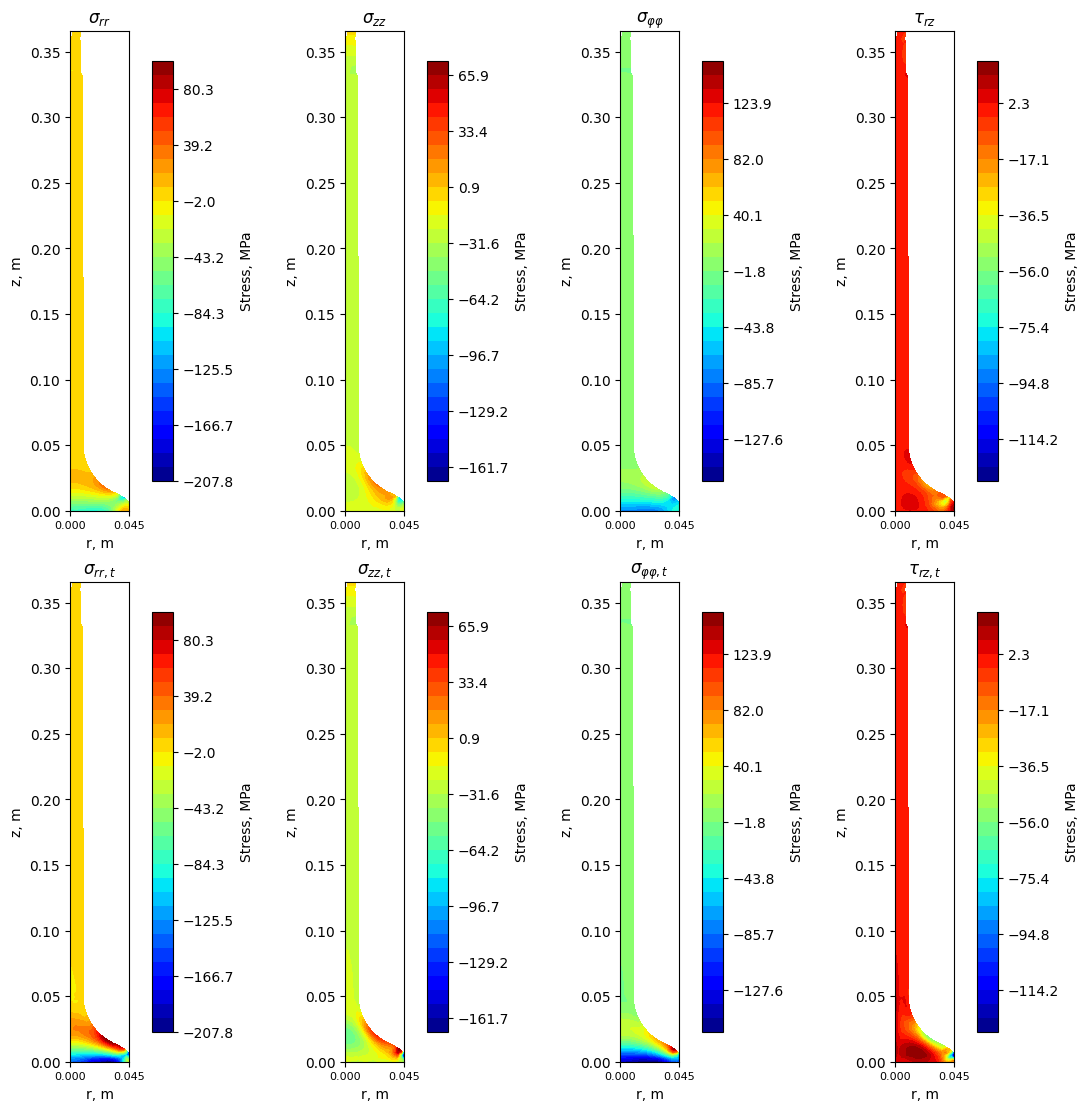

In [31]:
fig, axs = plt.subplots(2, 4, figsize=(11, 11), constrained_layout=True)
for column, ((mech_values, mech_title), (total_values, total_title)) in enumerate(
        zip(fields_sigma, fields_sigma_t)):
    # Both panels in a column use the same stress range and contour levels.
    mech_mpa = mech_values / 1e6
    total_mpa = total_values / 1e6
    vmin = min(mech_mpa.min(), total_mpa.min())
    vmax = max(mech_mpa.max(), total_mpa.max())
    if vmin == vmax:
        padding = max(abs(vmin), 1.0) * 1e-6
        vmin, vmax = vmin - padding, vmax + padding
    levels = np.linspace(vmin, vmax, 31)
    norm = Normalize(vmin=vmin, vmax=vmax)
    for row, values, title in [(0, mech_mpa, mech_title),
                               (1, total_mpa, total_title)]:
        ax = axs[row, column]
        im = ax.tricontourf(pnts[:, 0], pnts[:, 1], elms, values,
                           levels=levels, norm=norm, cmap="jet")
        fig.colorbar(im, ax=ax, label="Stress, MPa")
        ax.set(xlabel="r, m", ylabel="z, m", title=title)
        ax.set_aspect("equal")
        ax.set_xticks(np.linspace(*ax.get_xlim(), 2))
        ax.tick_params(axis="x", labelsize=8)

plt.show()

### 9.10. Deformed mesh comparison

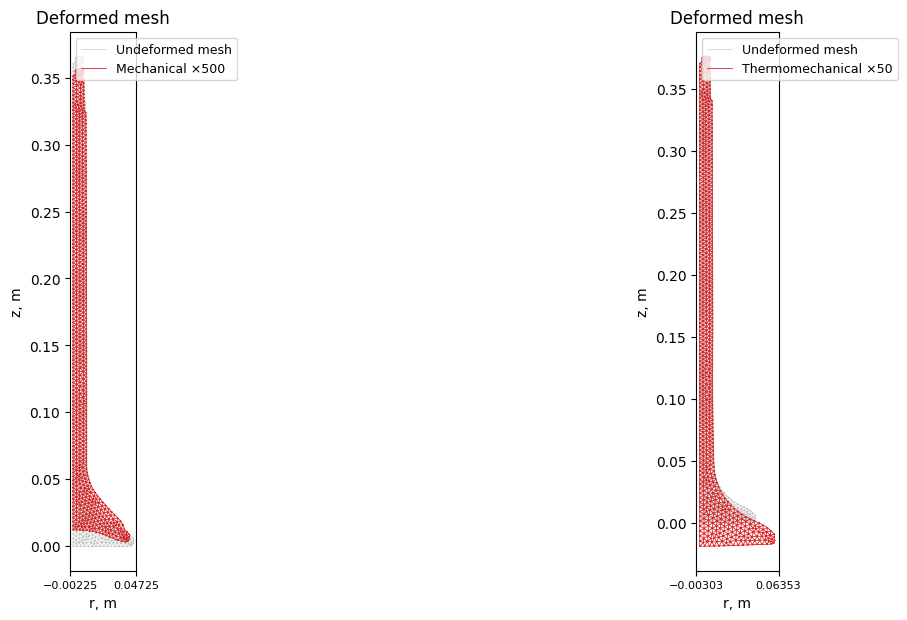

In [32]:
scale = 500     
scale_t = 50                                                  # Displacement magnification factor for visualization
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
axs[0].triplot(pnts[:, 0], pnts[:, 1], elms,
           lw=0.4, color="0.75", label="Undeformed mesh")
axs[0].triplot((pnts[:, 0] + scale*Ur),
           (pnts[:, 1] + scale*Uz),
           elms, lw=0.6, color="tab:red", label=f"Mechanical ×{scale:g}")
axs[1].triplot(pnts[:, 0], pnts[:, 1], elms,
           lw=0.4, color="0.75", label="Undeformed mesh")
axs[1].triplot((pnts[:, 0] + scale_t*Ur_t),
           (pnts[:, 1] + scale_t*Uz_t),
           elms, lw=0.6, color="tab:red", label=f"Thermomechanical ×{scale_t:g}")
[[ax.set(xlabel="r, m", ylabel="z, m", title="Deformed mesh"), ax.set_aspect("equal"), ax.legend(fontsize=9)] for ax in axs]
for ax in axs:
    ax.set_xticks(np.linspace(*ax.get_xlim(), 2))
    ax.tick_params(axis="x", labelsize=8)
plt.show()

## 10. Discussion questions and conclusions

Summarize the main findings of the thermomechanical stress and deformation analysis of the internal combustion engine valve, and answer the following questions.

1. How does the stiffness matrix of a linear triangular element in an axisymmetric problem differ from its plane-stress counterpart? Why must the circumferential strain $\varepsilon_{\varphi\varphi}=u_r/r$ be included in an axisymmetric formulation?

2. Why does the factor $2\pi r$ appear in the element stiffness matrix and equivalent nodal forces? How does this relate to the earlier thermal analysis of the piston?

3. Why is $\mathbf B$ not constant over the area of a linear triangular element in axisymmetric elasticity? What approximation is made when evaluating it at the triangle centroid?

4. What is the difference between total, elastic, and free thermal strains? Why does free thermal expansion alone not generate stress?

5. How are thermal strains included in the original finite element system of equations? Why, for constant elastic material properties, does the thermal effect change the right-hand side but not the stiffness matrix?

6. Why must free thermal strains be subtracted from total strains during stress recovery? Can $\mathbf D\boldsymbol{\varepsilon}_T$ be interpreted as the actual thermal stresses in the valve?

7. How does complete restraint of the seating face ($u_r=u_z=0$) differ from a support that permits sliding? How do changes in the boundary conditions affect displacements and stress distributions in the valve head?

8. Why can large temperature gradients produce peak stresses near the seating face and the transition from the valve head to the stem? How do geometry, constraints, and finite element size affect the result?

9. Can thermal loading decrease some stress components as well as increase others? Why must two analyses with identical mechanical loads be compared to assess the effect of heating?

10. What limitations does the adopted linear-elastic valve model have at high temperatures? Which additional physical phenomena would be needed for a more accurate analysis of an actual internal combustion engine valve?

### Results available for the report

The notebook already generates the following results:

- The valve finite element mesh, with physical groups identifying regions where boundary conditions are applied.
- The temperature distribution in the valve's meridional section, obtained in the previous seminar.
- Fields of radial displacement $u_r$, axial displacement $u_z$, and displacement magnitude $|\mathbf u|$ without thermal effects.
- Distributions of $\sigma_{rr}$, $\sigma_{zz}$, $\sigma_{\varphi\varphi}$, and $\tau_{rz}$ without thermal effects.
- Distributions of the same stress components with thermal effects.
- Deformed meshes for the mechanical-only and combined thermoelastic analyses.

### Optional further work for the report

The following results and checks require additional work and are not generated in this notebook:

- Corresponding displacement-field plots including thermal expansion.
- A comparative analysis of the stress change $\Delta\boldsymbol{\sigma}=\boldsymbol{\sigma}_{total}-\boldsymbol{\sigma}_{mech}$.
- The von Mises equivalent stress distribution, maximum values, and their locations.
- An assessment of how seating-face constraints affect the resulting stress and deformation state.
- Verification of the kinematic boundary conditions and mechanical equilibrium; where possible, a mesh-refinement convergence study.

When interpreting the results, remember that stresses near supports and geometric transitions may depend strongly on mesh size and the chosen boundary conditions. Local stress peaks should not be used directly to assess valve strength without further verification.

### Sources

1. **Previous seminar: thermal analysis of the valve.** Calculation of the steady-state temperature field used as input to the thermoelastic problem. The mesh and nodal temperatures are transferred from the thermal analysis to the structural analysis.

2. **Seminar on thermal analysis of the piston.** Axisymmetric finite element formulation, linear triangular elements, shape functions, geometric coefficients, and integration with the factor $2\pi r$.

3. **Seminar on the Kirsch problem.** Formation of the strain-displacement matrix $\mathbf B$, elastic constitutive matrix $\mathbf D$, and global system of equations; application of mechanical loads; and stress recovery.

4. **Textbook:** `chaynoff-fea.pdf`, Chapter 2, Section 2.4.2, “Analysis of the stress-strain state of engine components”: general principles of constructing a finite element model of an elastic body and forming its stiffness matrix.

> **Seminar outcome.** A finite element model of axisymmetric thermoelastic deformation of an internal combustion engine valve has been developed using a temperature field obtained from a separate thermal analysis. Mechanical and thermal effects are included in a common system of equilibrium equations. The resulting displacements and stresses enable investigation of the effects of temperature gradients and support conditions on the valve's stress and deformation state.